In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [38]:
df_2b = pd.read_csv('../results/eval_summary_2b.csv', header=0)
df_4b_fp8 = pd.read_csv('../results/eval_summary_4b_fp8.csv', header=0)
df_4b = pd.read_csv('../results/eval_summary_4b.csv', header=0)
df = pd.concat([df_2b, df_4b_fp8, df_4b], axis=0, ignore_index=True)
df

,timestamp,model_name,lora_adapter,samples,correct_count,accuracy,macro_f1,temperature,top_p,repetition_penalty,seed,num_frames,max_new_tokens,total_pixels,min_pixels,max_frames,sample_fps,inference_time,ann_file,video_root
0,20260226_112508,Qwen/Qwen3-VL-2B-Instruct,NaN,454.0,120.0,0.2643,0.2268,0.0,NaN,NaN,42,64,256,20971520,65536,2048,2,37.86,features/groundvqa/annotations.VRbin_00000_tes...,data/vrvideo_256/clips
1,20260226_112555,Qwen/Qwen3-VL-2B-Instruct,NaN,454.0,123.0,0.2709,0.2361,0.0,NaN,NaN,43,64,256,20971520,65536,2048,2,37.84,features/groundvqa/annotations.VRbin_00000_tes...,data/vrvideo_256/clips
2,20260226_112641,Qwen/Qwen3-VL-2B-Instruct,NaN,454.0,122.0,0.2687,0.2330,0.0,NaN,NaN,44,64,256,20971520,65536,2048,2,37.84,features/groundvqa/annotations.VRbin_00000_tes...,data/vrvideo_256/clips
3,20260226_112727,Qwen/Qwen3-VL-2B-Instruct,NaN,454.0,122.0,0.2687,0.2345,0.3,NaN,NaN,42,64,256,20971520,65536,2048,2,38.78,features/groundvqa/annotations.VRbin_00000_tes...,data/vrvideo_256/clips
4,20260226_112814,Qwen/Qwen3-VL-2B-Instruct,NaN,454.0,127.0,0.2797,0.2536,0.3,NaN,NaN,43,64,256,20971520,65536,2048,2,38.89,features/groundvqa/annotations.VRbin_00000_tes...,data/vrvideo_256/clips
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,20260226_144815,Qwen/Qwen3-VL-4B-Instruct,NaN,454.0,119.0,0.2621,0.2237,0.3,NaN,NaN,43,64,256,20971520,65536,2048,15,148.55,features/groundvqa/annotations.VRbin_00000_tes...,data/vrvideo_256/clips
104,20260226_145052,Qwen/Qwen3-VL-4B-Instruct,NaN,454.0,122.0,0.2687,0.2345,0.3,NaN,NaN,44,64,256,20971520,65536,2048,15,148.96,features/groundvqa/annotations.VRbin_00000_tes...,data/vrvideo_256/clips
105,20260226_145330,Qwen/Qwen3-VL-4B-Instruct,NaN,454.0,121.0,0.2665,0.2329,0.7,NaN,NaN,42,64,256,20971520,65536,2048,15,149.08,features/groundvqa/annotations.VRbin_00000_tes...,data/vrvideo_256/clips
106,20260226_145608,Qwen/Qwen3-VL-4B-Instruct,NaN,454.0,119.0,0.2621,0.2283,0.7,NaN,NaN,43,64,256,20971520,65536,2048,15,149.22,features/groundvqa/annotations.VRbin_00000_tes...,data/vrvideo_256/clips


In [39]:
df_avg = df.groupby(['model_name', 'temperature', 'sample_fps'])[['accuracy', 'macro_f1', 'inference_time']].mean().reset_index()
df_avg 

,model_name,temperature,sample_fps,accuracy,macro_f1,inference_time
0,Qwen/Qwen3-VL-2B-Instruct,0.0,2,0.267967,0.231967,37.846667
1,Qwen/Qwen3-VL-2B-Instruct,0.0,5,0.284100,0.256750,53.055000
2,Qwen/Qwen3-VL-2B-Instruct,0.0,10,0.283367,0.259600,74.566667
3,Qwen/Qwen3-VL-2B-Instruct,0.0,15,0.284100,0.262500,106.610000
4,Qwen/Qwen3-VL-2B-Instruct,0.3,2,0.276767,0.247333,38.820000
5,Qwen/Qwen3-VL-2B-Instruct,0.3,5,0.312800,0.295933,53.766667
6,Qwen/Qwen3-VL-2B-Instruct,0.3,10,0.305433,0.290033,75.390000
7,Qwen/Qwen3-VL-2B-Instruct,0.3,15,0.323067,0.313500,107.503333
8,Qwen/Qwen3-VL-2B-Instruct,0.7,2,0.320867,0.308233,38.400000
9,Qwen/Qwen3-VL-2B-Instruct,0.7,5,0.328933,0.320833,53.043333


In [32]:
import seaborn as sns

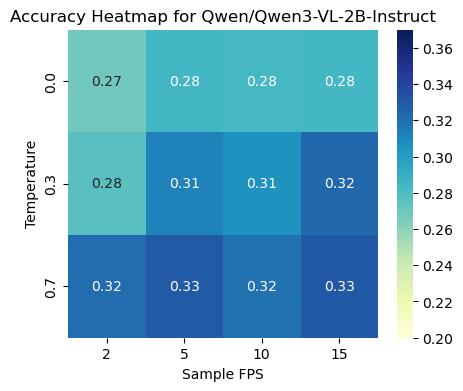

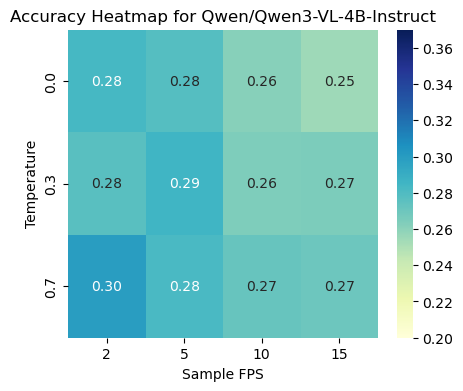

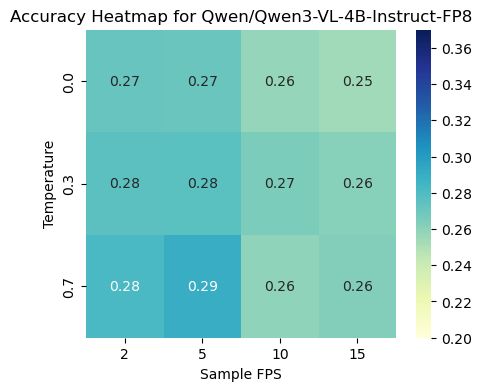

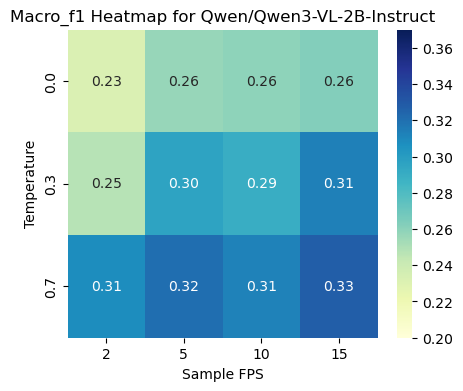

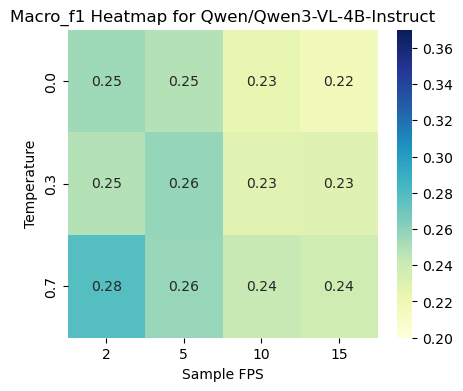

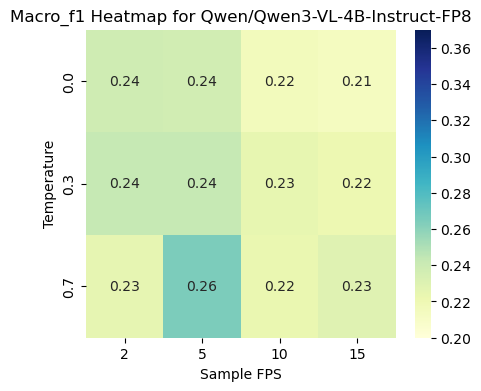

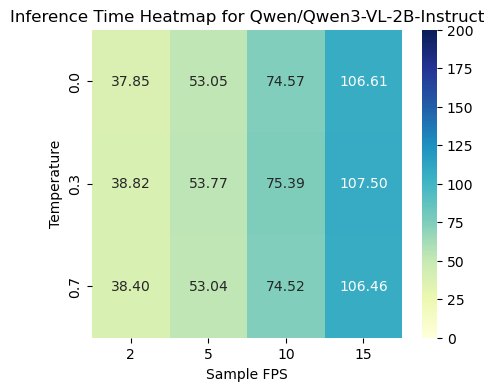

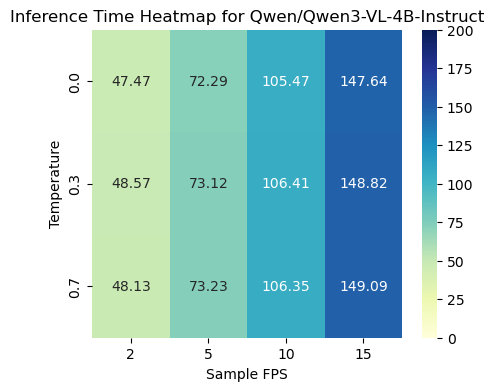

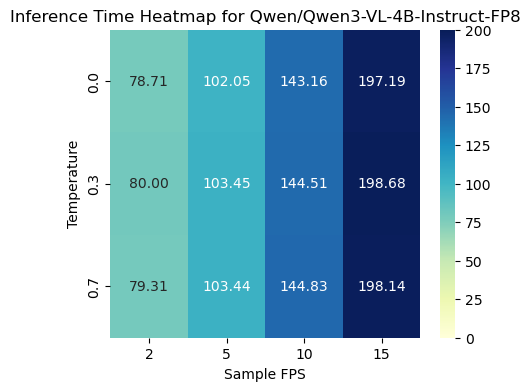

In [47]:
# plot a heatmap of accuracy for different temperature and sample_fps for each model
for model in df_avg['model_name'].unique():
    df_model = df_avg[df_avg['model_name'] == model]
    pivot_table = df_model.pivot(index='temperature', columns='sample_fps', values='accuracy')
    plt.figure(figsize=(5, 4))
    sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="YlGnBu", vmax=0.37, vmin=0.2)
    plt.title(f'Accuracy Heatmap for {model}')
    plt.ylabel('Temperature')
    plt.xlabel('Sample FPS')
    plt.savefig(f'../figures/qwen_eval/{model.split("/")[-1]}_accuracy_heatmap.png')
    plt.show()

# plot a heatmap of accuracy for different temperature and sample_fps for each model
for model in df_avg['model_name'].unique():
    df_model = df_avg[df_avg['model_name'] == model]
    pivot_table = df_model.pivot(index='temperature', columns='sample_fps', values='macro_f1')
    plt.figure(figsize=(5, 4))
    sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="YlGnBu", vmax=0.37, vmin=0.2)
    plt.title(f'Macro_f1 Heatmap for {model}')
    plt.ylabel('Temperature')
    plt.xlabel('Sample FPS')
    plt.savefig(f'../figures/qwen_eval/{model.split("/")[-1]}_macro_f1_heatmap.png')
    plt.show()

# plot a heatmap of accuracy for different temperature and sample_fps for each model
for model in df_avg['model_name'].unique():
    df_model = df_avg[df_avg['model_name'] == model]
    pivot_table = df_model.pivot(index='temperature', columns='sample_fps', values='inference_time')
    plt.figure(figsize=(5, 4))
    sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="YlGnBu", vmax=200, vmin=0)
    plt.title(f'Inference Time Heatmap for {model}')
    plt.ylabel('Temperature')
    plt.xlabel('Sample FPS')
    plt.savefig(f'../figures/qwen_eval/{model.split("/")[-1]}_inference_time_heatmap.png')
    plt.show()

In [65]:
df_lora_2b = pd.read_csv('../results/qwen_train_summary_2b.csv', header=0)
df_lora_2b

,log_path,model_name,epochs,batch_size,lr,ft_type,lora_rank,lora_alpha,random_seed,monitor,...,deterministic_test_acc,deterministic_test_macro_f1,deterministic_inference_time,default_test_acc,default_test_macro_f1,default_inference_time,saved_checkpoints,ann_file_train,ann_file_val,ann_file_test
0,20260226_162620,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_llm_attn_qv,8,16,42,val_macro_f1,...,0.6520,0.5682,29.94,0.6542,0.5656,30.33,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...
1,20260226_163522,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_llm_attn_qkvo,8,16,42,val_macro_f1,...,0.5947,0.5191,32.55,0.6145,0.5491,32.98,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...
2,20260226_164455,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_llm_mlp,8,16,42,val_macro_f1,...,0.6410,0.5347,31.42,0.6520,0.5346,32.01,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...
3,20260226_165439,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_llm_attn_mlp,8,16,42,val_macro_f1,...,0.6189,0.5715,37.14,0.6344,0.5854,37.57,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...
4,20260226_170525,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_llm_vlm_bridger,8,16,42,val_macro_f1,...,0.6322,0.5850,38.83,0.6366,0.5828,39.28,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...
5,20260226_171903,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_vlm_bridger,8,16,42,val_macro_f1,...,0.6696,0.5415,28.56,0.6696,0.5658,29.02,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...
6,20260226_173027,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_llm_attn_qv,8,16,42,val_macro_f1,...,0.5859,0.5272,29.74,0.5639,0.5120,30.16,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...
7,20260226_173931,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_llm_attn_qkvo,8,16,42,val_macro_f1,...,0.6278,0.5201,32.45,0.6476,0.5420,32.96,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...
8,20260226_174904,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_llm_mlp,8,16,42,val_macro_f1,...,0.6410,0.5347,31.50,0.6432,0.5310,32.08,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...
9,20260226_175848,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_llm_attn_mlp,8,16,42,val_macro_f1,...,0.6189,0.5715,37.22,0.6256,0.5739,37.59,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...


In [59]:
df_lora_avg = df_lora_2b.groupby(['model_name', 'eval_deterministic', 'ft_type'])[['deterministic_test_acc', 'deterministic_test_macro_f1', 'default_test_acc', 'default_test_macro_f1']].mean().reset_index()
df_lora_avg

,model_name,eval_deterministic,ft_type,deterministic_test_acc,deterministic_test_macro_f1,default_test_acc,default_test_macro_f1
0,Qwen/Qwen3-VL-2B-Instruct,False,lora_llm_attn_mlp,0.618900,0.571500,0.625600,0.573900
1,Qwen/Qwen3-VL-2B-Instruct,False,lora_llm_attn_qkvo,0.627800,0.520100,0.647600,0.542000
2,Qwen/Qwen3-VL-2B-Instruct,False,lora_llm_attn_qv,0.585900,0.527200,0.563900,0.512000
3,Qwen/Qwen3-VL-2B-Instruct,False,lora_llm_mlp,0.641000,0.534700,0.643200,0.531000
4,Qwen/Qwen3-VL-2B-Instruct,False,lora_llm_vlm_bridger,0.572700,0.524900,0.572700,0.533200
5,Qwen/Qwen3-VL-2B-Instruct,False,lora_vlm_bridger,0.632200,0.546800,0.636600,0.550100
6,Qwen/Qwen3-VL-2B-Instruct,True,lora_llm_attn_mlp,0.613271,0.536800,0.631857,0.555571
7,Qwen/Qwen3-VL-2B-Instruct,True,lora_llm_attn_qkvo,0.632143,0.536971,0.656071,0.567243
8,Qwen/Qwen3-VL-2B-Instruct,True,lora_llm_attn_qv,0.620514,0.546429,0.633743,0.556429
9,Qwen/Qwen3-VL-2B-Instruct,True,lora_llm_mlp,0.605743,0.519386,0.618643,0.530814


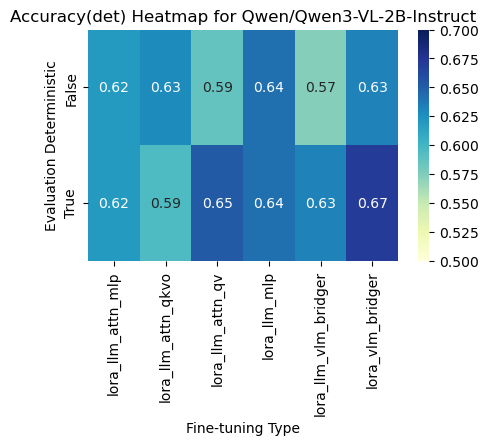

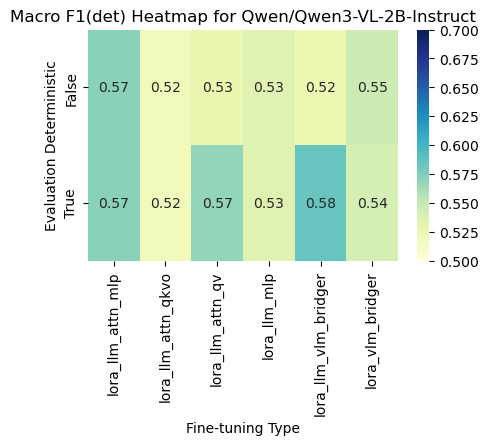

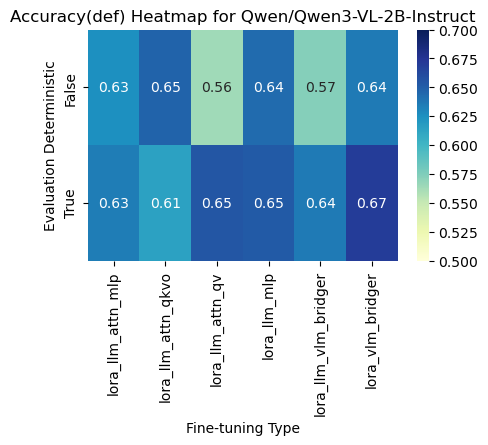

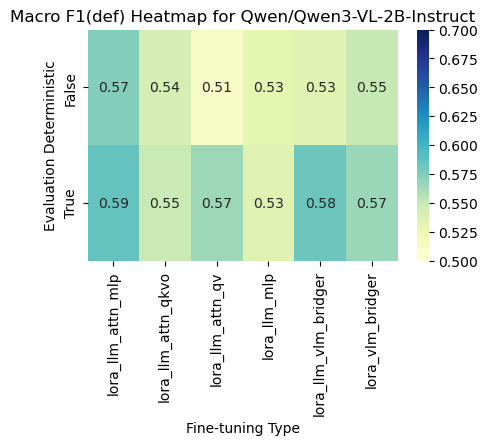

In [57]:
for model in df_lora_avg['model_name'].unique():
    df_model = df_lora_avg[df_lora_avg['model_name'] == model]
    pivot_table = df_model.pivot(index='eval_deterministic', columns='ft_type', values='deterministic_test_acc')
    plt.figure(figsize=(5, 3))
    sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="YlGnBu", vmax=0.7, vmin=0.5)
    plt.title(f'Accuracy(det) Heatmap for {model}')
    plt.ylabel('Evaluation Deterministic')
    plt.xlabel('Fine-tuning Type')
    plt.savefig(f'../figures/qwen_train/{model.split("/")[-1]}_accuracy_det_heatmap.png')
    plt.show()

for model in df_lora_avg['model_name'].unique():
    df_model = df_lora_avg[df_lora_avg['model_name'] == model]
    pivot_table = df_model.pivot(index='eval_deterministic', columns='ft_type', values='deterministic_test_macro_f1')
    plt.figure(figsize=(5, 3))
    sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="YlGnBu", vmax=0.7, vmin=0.5)
    plt.title(f'Macro F1(det) Heatmap for {model}')
    plt.ylabel('Evaluation Deterministic')
    plt.xlabel('Fine-tuning Type')
    plt.savefig(f'../figures/qwen_train/{model.split("/")[-1]}_macro_f1_det_heatmap.png')
    plt.show()

for model in df_lora_avg['model_name'].unique():
    df_model = df_lora_avg[df_lora_avg['model_name'] == model]
    pivot_table = df_model.pivot(index='eval_deterministic', columns='ft_type', values='default_test_acc')
    plt.figure(figsize=(5, 3))
    sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="YlGnBu", vmax=0.7, vmin=0.5)
    plt.title(f'Accuracy(def) Heatmap for {model}')
    plt.ylabel('Evaluation Deterministic')
    plt.xlabel('Fine-tuning Type')
    plt.savefig(f'../figures/qwen_train/{model.split("/")[-1]}_accuracy_def_heatmap.png')
    plt.show()

for model in df_lora_avg['model_name'].unique():
    df_model = df_lora_avg[df_lora_avg['model_name'] == model]
    pivot_table = df_model.pivot(index='eval_deterministic', columns='ft_type', values='default_test_macro_f1')
    plt.figure(figsize=(5, 3))
    sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="YlGnBu", vmax=0.7, vmin=0.5)
    plt.title(f'Macro F1(def) Heatmap for {model}')
    plt.ylabel('Evaluation Deterministic')
    plt.xlabel('Fine-tuning Type')
    plt.savefig(f'../figures/qwen_train/{model.split("/")[-1]}_macro_f1_def_heatmap.png')
    plt.show()

In [61]:
df_lora_2b.columns

Index(['log_path', 'model_name', 'epochs', 'batch_size', 'lr', 'ft_type',
       'lora_rank', 'lora_alpha', 'random_seed', 'monitor', 'top_k',
       'eval_deterministic', 'eval_max_new_tokens', 'eval_batch_size',
       'model_total_params', 'model_trainable_params',
       'model_non_trainable_params', 'best_val_epoch', 'best_val_macro_f1',
       'best_val_acc_at_best_epoch', 'deterministic_test_acc',
       'deterministic_test_macro_f1', 'deterministic_inference_time',
       'default_test_acc', 'default_test_macro_f1', 'default_inference_time',
       'saved_checkpoints', 'ann_file_train', 'ann_file_val', 'ann_file_test'],
      dtype='object')

In [66]:
df_lora_filtered = df_lora_2b[(df_lora_2b['eval_deterministic'] == True)]
df_lora_filtered

,log_path,model_name,epochs,batch_size,lr,ft_type,lora_rank,lora_alpha,random_seed,monitor,...,deterministic_test_acc,deterministic_test_macro_f1,deterministic_inference_time,default_test_acc,default_test_macro_f1,default_inference_time,saved_checkpoints,ann_file_train,ann_file_val,ann_file_test
0,20260226_162620,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_llm_attn_qv,8,16,42,val_macro_f1,...,0.6520,0.5682,29.94,0.6542,0.5656,30.33,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...
1,20260226_163522,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_llm_attn_qkvo,8,16,42,val_macro_f1,...,0.5947,0.5191,32.55,0.6145,0.5491,32.98,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...
2,20260226_164455,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_llm_mlp,8,16,42,val_macro_f1,...,0.6410,0.5347,31.42,0.6520,0.5346,32.01,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...
3,20260226_165439,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_llm_attn_mlp,8,16,42,val_macro_f1,...,0.6189,0.5715,37.14,0.6344,0.5854,37.57,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...
4,20260226_170525,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_llm_vlm_bridger,8,16,42,val_macro_f1,...,0.6322,0.5850,38.83,0.6366,0.5828,39.28,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...
5,20260226_171903,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_vlm_bridger,8,16,42,val_macro_f1,...,0.6696,0.5415,28.56,0.6696,0.5658,29.02,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...
12,20260226_194827,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_llm_attn_qv,2,8,42,val_macro_f1,...,0.6123,0.5558,29.81,0.6278,0.5679,30.42,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...
13,20260226_195728,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_llm_attn_qv,2,16,42,val_macro_f1,...,0.6145,0.5622,29.81,0.6278,0.5628,30.23,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...
14,20260226_200629,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_llm_attn_qv,2,32,42,val_macro_f1,...,0.5573,0.5129,29.91,0.5859,0.5424,30.32,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...
15,20260226_201531,Qwen/Qwen3-VL-2B-Instruct,10,4,0.0001,lora_llm_attn_qv,4,8,42,val_macro_f1,...,0.6432,0.5310,29.77,0.6696,0.5582,30.22,outputs/qwen_train/Qwen3-VL-2B-Instruct/202602...,features/groundvqa/annotations.VRbin_00000_tra...,features/groundvqa/annotations.VRbin_00000_val...,features/groundvqa/annotations.VRbin_00000_tes...


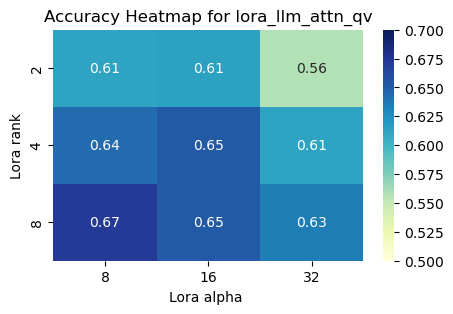

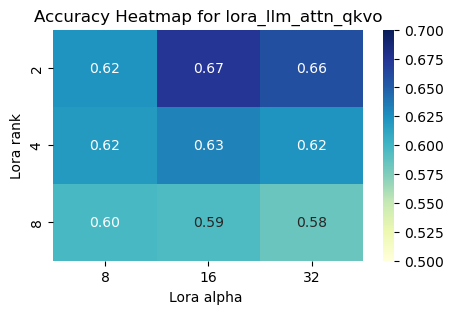

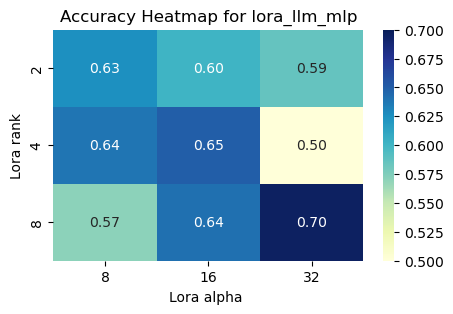

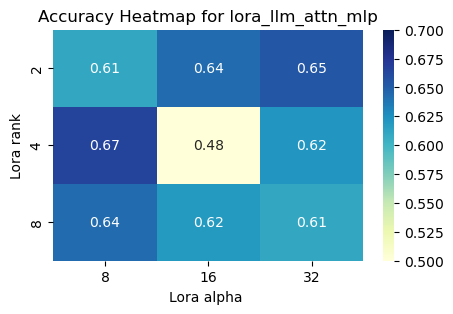

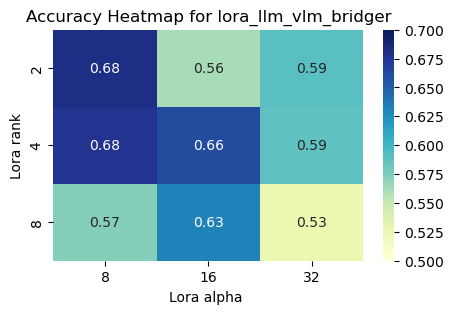

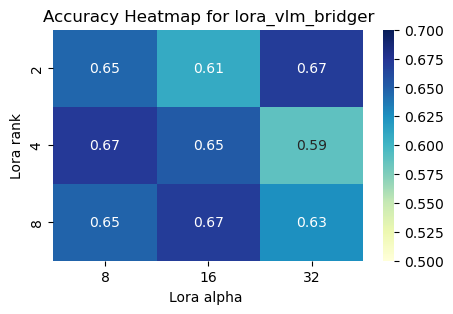

In [70]:
for ft_type in df_lora_filtered['ft_type'].unique():
    df_model = df_lora_filtered[df_lora_filtered['ft_type'] == ft_type]
    pivot_table = df_model.pivot(index='lora_rank', columns='lora_alpha', values='deterministic_test_acc')
    plt.figure(figsize=(5, 3))
    sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="YlGnBu", vmax=0.7, vmin=0.5)
    plt.title(f'Accuracy Heatmap for {ft_type}')
    plt.ylabel('Lora rank')
    plt.xlabel('Lora alpha ')
    # plt.savefig(f'../figures/qwen_train/{ft_type}_accuracy_heatmap.png')
    plt.show()

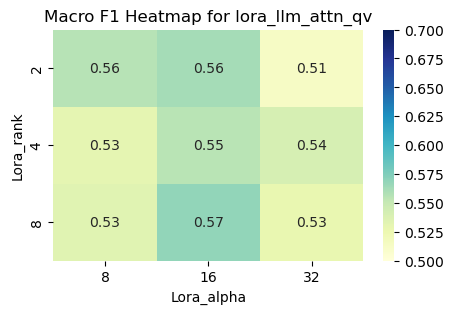

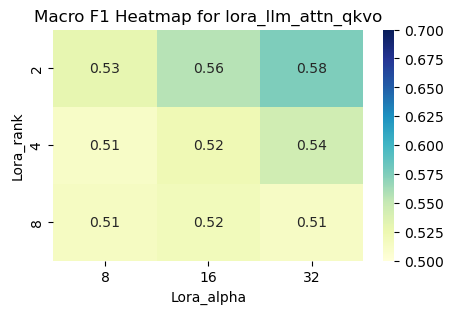

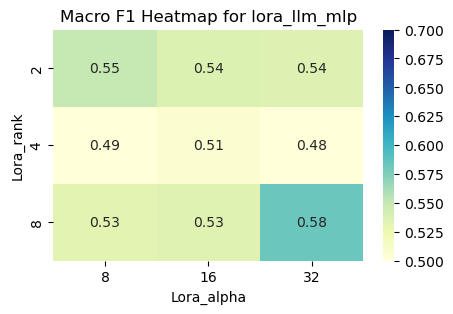

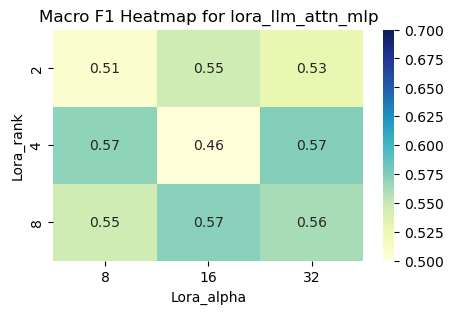

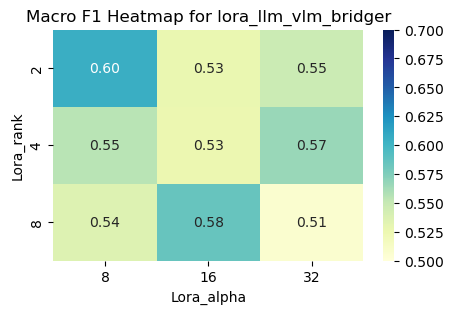

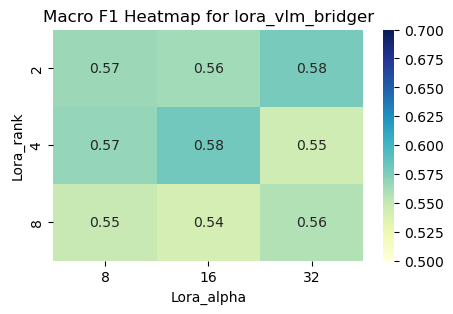

In [71]:
for ft_type in df_lora_filtered['ft_type'].unique():
    df_model = df_lora_filtered[df_lora_filtered['ft_type'] == ft_type]
    pivot_table = df_model.pivot(index='lora_rank', columns='lora_alpha', values='deterministic_test_macro_f1')
    plt.figure(figsize=(5, 3))
    sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="YlGnBu", vmax=0.7, vmin=0.5)
    plt.title(f'Macro F1 Heatmap for {ft_type}')
    plt.ylabel('Lora_rank')
    plt.xlabel('Lora_alpha')
    # plt.savefig(f'../figures/qwen_train/{ft_type}_macro_f1_det_heatmap.png')
    plt.show()